# Deep Learning

## Project: Stock Market Trend Classification Using LSTM

This project follows the structure of the **Chapter 13: Store Sales Timeseries** notebook, adapting its data preparation, visualization, chronological splitting, scaling, sliding-window generation, recurrent neural network training, and baseline comparison to a stock market classification task.

Instead of predicting the exact stock price, the goal is to classify whether a stock's closing price will increase or not on the next trading day.

**Project objectives**
- Load historical stock data from the Kaggle dataset using kagglehub.
- Focus on three stocks: Apple (AAPL), Microsoft (MSFT), and Tesla (TSLA).
- Create a binary target based on the next trading day's closing price.
- Engineer financial features, including daily returns, moving averages, rolling volatility, volume changes, RSI, and MACD.
- Visualize stock prices, class distributions, and feature relationships.
- Use a sliding window to construct sequential data for an LSTM model.
- Train Logistic Regression as a baseline and LSTM as the recurrent neural network.
- Evaluate both models using Accuracy, Precision, Recall, F1-score, a confusion matrix, and ROC-AUC.
Important distinction: This is a classification problem, not a stock-price regression problem. The models predict a probability of the next day's price increasing, not the future price itself.

### Import required libraries



In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    classification_report,
    RocCurveDisplay
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### Define project settings

The window length is configurable. We can experiment with 10, 20, and 30 trading days to investigate whether a longer historical context improves performance.

In [2]:
TICKERS = ["AAPL", "MSFT", "TSLA"]

# Number of historical trading days used by the LSTM
TIMESTEPS = 20

# Chronological split
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Training settings
EPOCHS = 50
BATCH_SIZE = 32

print("Selected stocks:", TICKERS)
print("Sliding window:", TIMESTEPS, "trading days")

Selected stocks: ['AAPL', 'MSFT', 'TSLA']
Sliding window: 20 trading days


### 1. Load and explore the dataset

**1.1. Download the Kaggle dataset**

Use the supplied dataset identifier to download the latest available dataset version.

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jacksoncrow/stock-market-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'stock-market-dataset' dataset.
Path to dataset files: /kaggle/input/stock-market-dataset


The downloaded dataset may contain multiple CSV files organized into subdirectories. The following cell inspects the files rather than assuming a fixed folder structure.

In [4]:
csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

print("Number of CSV files:", len(csv_files))

for file in csv_files[:20]:
    print(file)

Number of CSV files: 8050
/kaggle/input/stock-market-dataset/symbols_valid_meta.csv
/kaggle/input/stock-market-dataset/stocks/MTL.csv
/kaggle/input/stock-market-dataset/stocks/JOE.csv
/kaggle/input/stock-market-dataset/stocks/DRE.csv
/kaggle/input/stock-market-dataset/stocks/CTY.csv
/kaggle/input/stock-market-dataset/stocks/AMSF.csv
/kaggle/input/stock-market-dataset/stocks/IMH.csv
/kaggle/input/stock-market-dataset/stocks/GFL.csv
/kaggle/input/stock-market-dataset/stocks/CLM.csv
/kaggle/input/stock-market-dataset/stocks/UBER.csv
/kaggle/input/stock-market-dataset/stocks/NEBU.csv
/kaggle/input/stock-market-dataset/stocks/SGB.csv
/kaggle/input/stock-market-dataset/stocks/WWW.csv
/kaggle/input/stock-market-dataset/stocks/UTSI.csv
/kaggle/input/stock-market-dataset/stocks/PBB.csv
/kaggle/input/stock-market-dataset/stocks/UFCS.csv
/kaggle/input/stock-market-dataset/stocks/ZM.csv
/kaggle/input/stock-market-dataset/stocks/DCPH.csv
/kaggle/input/stock-market-dataset/stocks/HALL.csv
/kaggle/in

**1.2. Load the three selected stocks**

Stock data may be stored in separate files such as AAPL.csv, MSFT.csv, and TSLA.csv. The helper function below searches for a CSV file matching each ticker and verifies that the required columns exist.

In [5]:
def load_stock_data(root_path, ticker):
    matching_files = [
        file for file in glob.glob(
            os.path.join(root_path, "**", "*.csv"),
            recursive=True
        )
        if os.path.basename(file).upper() == f"{ticker}.CSV"
    ]

    if not matching_files:
        raise FileNotFoundError(
            f"Could not find {ticker}.csv in {root_path}. "
            "Inspect the CSV file list and update the file lookup."
        )

    df_stock = pd.read_csv(matching_files[0])

    # Normalize column names
    df_stock.columns = [
        col.strip().title() for col in df_stock.columns
    ]

    # Some datasets use Ticker instead of Symbol
    if "Symbol" not in df_stock.columns:
        if "Ticker" in df_stock.columns:
            df_stock = df_stock.rename(
                columns={"Ticker": "Symbol"}
            )
        else:
            df_stock[
                "Symbol"
            ] = ticker

    required_columns = [
        "Date", "Open", "High", "Low",
        "Close", "Volume", "Symbol"
    ]

    missing_columns = [
        col for col in required_columns
        if col not in df_stock.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{ticker} is missing columns: {missing_columns}"
        )

    df_stock[
        "Symbol"
    ] = ticker

    return df_stock


stock_data = pd.concat(
    [load_stock_data(path, ticker) for ticker in TICKERS],
    ignore_index=True
)

print("Dataset shape:", stock_data.shape)

for ticker in TICKERS:
    print(f"\nFirst 10 entries for {ticker}:")
    display(stock_data[stock_data["Symbol"] == ticker].head(10))

Dataset shape: (20950, 8)

First 10 entries for AAPL:


,Date,Open,High,Low,Close,Adj Close,Volume,Symbol
0,1980-12-12,0.513393,0.515625,0.513393,0.513393,0.406782,117258400,AAPL
1,1980-12-15,0.488839,0.488839,0.486607,0.486607,0.385558,43971200,AAPL
2,1980-12-16,0.453125,0.453125,0.450893,0.450893,0.357260,26432000,AAPL
3,1980-12-17,0.462054,0.464286,0.462054,0.462054,0.366103,21610400,AAPL
4,1980-12-18,0.475446,0.477679,0.475446,0.475446,0.376715,18362400,AAPL
5,1980-12-19,0.504464,0.506696,0.504464,0.504464,0.399707,12157600,AAPL
6,1980-12-22,0.529018,0.531250,0.529018,0.529018,0.419162,9340800,AAPL
7,1980-12-23,0.551339,0.553571,0.551339,0.551339,0.436848,11737600,AAPL
8,1980-12-24,0.580357,0.582589,0.580357,0.580357,0.459840,12000800,AAPL
9,1980-12-26,0.633929,0.636161,0.633929,0.633929,0.502287,13893600,AAPL



First 10 entries for MSFT:


,Date,Open,High,Low,Close,Adj Close,Volume,Symbol
9909,1986-03-13,0.088542,0.101562,0.088542,0.097222,0.062378,1031788800,MSFT
9910,1986-03-14,0.097222,0.102431,0.097222,0.100694,0.064606,308160000,MSFT
9911,1986-03-17,0.100694,0.103299,0.100694,0.102431,0.065720,133171200,MSFT
9912,1986-03-18,0.102431,0.103299,0.098958,0.099826,0.064049,67766400,MSFT
9913,1986-03-19,0.099826,0.100694,0.097222,0.098090,0.062935,47894400,MSFT
9914,1986-03-20,0.098090,0.098090,0.094618,0.095486,0.061264,58435200,MSFT
9915,1986-03-21,0.095486,0.097222,0.091146,0.092882,0.059594,59990400,MSFT
9916,1986-03-24,0.092882,0.092882,0.089410,0.090278,0.057923,65289600,MSFT
9917,1986-03-25,0.090278,0.092014,0.089410,0.092014,0.059037,32083200,MSFT
9918,1986-03-26,0.092014,0.095486,0.091146,0.094618,0.060707,22752000,MSFT



First 10 entries for TSLA:


,Date,Open,High,Low,Close,Adj Close,Volume,Symbol
18493,2010-06-29,19.000000,25.000000,17.540001,23.889999,23.889999,18766300,TSLA
18494,2010-06-30,25.790001,30.420000,23.299999,23.830000,23.830000,17187100,TSLA
18495,2010-07-01,25.000000,25.920000,20.270000,21.959999,21.959999,8218800,TSLA
18496,2010-07-02,23.000000,23.100000,18.709999,19.200001,19.200001,5139800,TSLA
18497,2010-07-06,20.000000,20.000000,15.830000,16.110001,16.110001,6866900,TSLA
18498,2010-07-07,16.400000,16.629999,14.980000,15.800000,15.800000,6921700,TSLA
18499,2010-07-08,16.139999,17.520000,15.570000,17.459999,17.459999,7711400,TSLA
18500,2010-07-09,17.580000,17.900000,16.549999,17.400000,17.400000,4050600,TSLA
18501,2010-07-12,17.950001,18.070000,17.000000,17.049999,17.049999,2202500,TSLA
18502,2010-07-13,17.389999,18.639999,16.900000,18.139999,18.139999,2680100,TSLA


The Adj Close column is useful for analyses that account for historical stock splits and dividends. This project uses the raw Close column for its target, as specified in the project definition.

If the downloaded files use a different layout, inspect the output of the CSV listing and adjust the file lookup rather than assuming the dataset is missing.

**1.3. Inspect the data**

We should confirm that all three stocks have sufficient historical observations, valid numerical values, and a consistent date format before feature engineering.

In [6]:
print("Dataset shape:", stock_data.shape)
print("\nColumn information:")
stock_data.info()

print("\nMissing values:")
display(stock_data.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", stock_data.duplicated().sum())

print("\nDate range:")
print(stock_data["Date"].min(), "to", stock_data["Date"].max())

print("\nSamples per ticker:")
display(stock_data["Symbol"].value_counts().to_frame("Rows"))

Dataset shape: (20950, 8)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20950 entries, 0 to 20949
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       20950 non-null  object 
 1   Open       20950 non-null  float64
 2   High       20950 non-null  float64
 3   Low        20950 non-null  float64
 4   Close      20950 non-null  float64
 5   Adj Close  20950 non-null  float64
 6   Volume     20950 non-null  int64  
 7   Symbol     20950 non-null  object 
dtypes: float64(5), int64(1), object(2)
memory usage: 1.3+ MB

Missing values:


,Missing Values
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0
Symbol,0



Duplicate rows: 0

Date range:
1980-12-12 to 2020-04-01

Samples per ticker:


,Rows
Symbol,
AAPL,9909
MSFT,8584
TSLA,2457


**1.4. Convert dates and sort observations**

Time-series observations must be ordered chronologically. Otherwise, the next-row target and rolling features would not represent the intended sequence.

Each stock is sorted independently by date. This is important because the previous observation for Apple must never become the previous observation for Microsoft or Tesla.

In [7]:
stock_data["Date"] = pd.to_datetime(
    stock_data["Date"], errors="coerce"
)

numeric_columns = [
    "Open", "High", "Low", "Close", "Volume"
]

if "Adj Close" in stock_data.columns:
    numeric_columns.append("Adj Close")

for col in numeric_columns:
    stock_data[col] = pd.to_numeric(
        stock_data[col], errors="coerce"
    )

stock_data = (
    stock_data
    .dropna(subset=["Date", "Close", "Volume"])
    .drop_duplicates(subset=["Date", "Symbol"])
    .sort_values(["Symbol", "Date"])
    .reset_index(drop=True)
)

print("Cleaned dataset shape:", stock_data.shape)
for i in range(3):
    print(f"\nFirst 10 entries for {TICKERS[i]}:")
    display(stock_data[stock_data["Symbol"] == TICKERS[i]].head(10))

Cleaned dataset shape: (20950, 8)

First 10 entries for AAPL:


,Date,Open,High,Low,Close,Adj Close,Volume,Symbol
0,1980-12-12,0.513393,0.515625,0.513393,0.513393,0.406782,117258400,AAPL
1,1980-12-15,0.488839,0.488839,0.486607,0.486607,0.385558,43971200,AAPL
2,1980-12-16,0.453125,0.453125,0.450893,0.450893,0.357260,26432000,AAPL
3,1980-12-17,0.462054,0.464286,0.462054,0.462054,0.366103,21610400,AAPL
4,1980-12-18,0.475446,0.477679,0.475446,0.475446,0.376715,18362400,AAPL
5,1980-12-19,0.504464,0.506696,0.504464,0.504464,0.399707,12157600,AAPL
6,1980-12-22,0.529018,0.531250,0.529018,0.529018,0.419162,9340800,AAPL
7,1980-12-23,0.551339,0.553571,0.551339,0.551339,0.436848,11737600,AAPL
8,1980-12-24,0.580357,0.582589,0.580357,0.580357,0.459840,12000800,AAPL
9,1980-12-26,0.633929,0.636161,0.633929,0.633929,0.502287,13893600,AAPL



First 10 entries for MSFT:


,Date,Open,High,Low,Close,Adj Close,Volume,Symbol
9909,1986-03-13,0.088542,0.101562,0.088542,0.097222,0.062378,1031788800,MSFT
9910,1986-03-14,0.097222,0.102431,0.097222,0.100694,0.064606,308160000,MSFT
9911,1986-03-17,0.100694,0.103299,0.100694,0.102431,0.065720,133171200,MSFT
9912,1986-03-18,0.102431,0.103299,0.098958,0.099826,0.064049,67766400,MSFT
9913,1986-03-19,0.099826,0.100694,0.097222,0.098090,0.062935,47894400,MSFT
9914,1986-03-20,0.098090,0.098090,0.094618,0.095486,0.061264,58435200,MSFT
9915,1986-03-21,0.095486,0.097222,0.091146,0.092882,0.059594,59990400,MSFT
9916,1986-03-24,0.092882,0.092882,0.089410,0.090278,0.057923,65289600,MSFT
9917,1986-03-25,0.090278,0.092014,0.089410,0.092014,0.059037,32083200,MSFT
9918,1986-03-26,0.092014,0.095486,0.091146,0.094618,0.060707,22752000,MSFT



First 10 entries for TSLA:


,Date,Open,High,Low,Close,Adj Close,Volume,Symbol
18493,2010-06-29,19.000000,25.000000,17.540001,23.889999,23.889999,18766300,TSLA
18494,2010-06-30,25.790001,30.420000,23.299999,23.830000,23.830000,17187100,TSLA
18495,2010-07-01,25.000000,25.920000,20.270000,21.959999,21.959999,8218800,TSLA
18496,2010-07-02,23.000000,23.100000,18.709999,19.200001,19.200001,5139800,TSLA
18497,2010-07-06,20.000000,20.000000,15.830000,16.110001,16.110001,6866900,TSLA
18498,2010-07-07,16.400000,16.629999,14.980000,15.800000,15.800000,6921700,TSLA
18499,2010-07-08,16.139999,17.520000,15.570000,17.459999,17.459999,7711400,TSLA
18500,2010-07-09,17.580000,17.900000,16.549999,17.400000,17.400000,4050600,TSLA
18501,2010-07-12,17.950001,18.070000,17.000000,17.049999,17.049999,2202500,TSLA
18502,2010-07-13,17.389999,18.639999,16.900000,18.139999,18.139999,2680100,TSLA


### 2. Feature engineering and target creation

**2.1. Define the target variable**

For each stock, the target is defined as:

$$
y_t =
\begin{cases}
1 & \text{if } Close_{t+1} > Close_t\\
0 & \text{if } Close_{t+1} \leq Close_t
\end{cases}
$$

Here, \(t\) represents the current trading day and \(t+1\) the next available trading-day observation for the same stock.
- 1: the next closing price increases.
- 0: the next closing price stays the same or decreases.
We use `shift(-5)` to obtain the next 5 observed closing price. The final observation of each ticker has no known next-day target and must be removed.

In [8]:
stock_data["Next_Close"] = (
    stock_data.groupby("Symbol")["Close"].shift(-5)
)

stock_data["Target"] = (
    stock_data["Next_Close"] > stock_data["Close"]
).astype(int)

# The final 5 observations for each stock have no next 5-day close
stock_data = stock_data.dropna(
    subset=["Next_Close"]
).reset_index(drop=True)

stock_data["Target"] = stock_data["Target"].astype(int)

for ticker in TICKERS:
    print(f"\nFirst 10 entries for {ticker}:")
    display(stock_data[stock_data["Symbol"] == ticker]
     [["Date", "Symbol", "Close", "Next_Close", "Target"]].head(10))


First 10 entries for AAPL:


,Date,Symbol,Close,Next_Close,Target
0,1980-12-12,AAPL,0.513393,0.504464,0
1,1980-12-15,AAPL,0.486607,0.529018,1
2,1980-12-16,AAPL,0.450893,0.551339,1
3,1980-12-17,AAPL,0.462054,0.580357,1
4,1980-12-18,AAPL,0.475446,0.633929,1
5,1980-12-19,AAPL,0.504464,0.642857,1
6,1980-12-22,AAPL,0.529018,0.627232,1
7,1980-12-23,AAPL,0.551339,0.609375,1
8,1980-12-24,AAPL,0.580357,0.616071,1
9,1980-12-26,AAPL,0.633929,0.602679,0



First 10 entries for MSFT:


,Date,Symbol,Close,Next_Close,Target
9904,1986-03-13,MSFT,0.097222,0.095486,0
9905,1986-03-14,MSFT,0.100694,0.092882,0
9906,1986-03-17,MSFT,0.102431,0.090278,0
9907,1986-03-18,MSFT,0.099826,0.092014,0
9908,1986-03-19,MSFT,0.098090,0.094618,0
9909,1986-03-20,MSFT,0.095486,0.096354,1
9910,1986-03-21,MSFT,0.092882,0.095486,1
9911,1986-03-24,MSFT,0.090278,0.094618,1
9912,1986-03-25,MSFT,0.092014,0.095486,1
9913,1986-03-26,MSFT,0.094618,0.096354,1



First 10 entries for TSLA:


,Date,Symbol,Close,Next_Close,Target
18483,2010-06-29,TSLA,23.889999,15.800000,0
18484,2010-06-30,TSLA,23.830000,17.459999,0
18485,2010-07-01,TSLA,21.959999,17.400000,0
18486,2010-07-02,TSLA,19.200001,17.049999,0
18487,2010-07-06,TSLA,16.110001,18.139999,1
18488,2010-07-07,TSLA,15.800000,19.840000,1
18489,2010-07-08,TSLA,17.459999,19.889999,1
18490,2010-07-09,TSLA,17.400000,20.639999,1
18491,2010-07-12,TSLA,17.049999,21.910000,1
18492,2010-07-13,TSLA,18.139999,20.299999,1


**Interpretation:** If Apple's closing price on the next observed trading day is higher than today's closing price, the target is 1; otherwise, it is 0.

**2.2. Calculate daily returns**

Daily return measures the relative change in closing price from the previous trading day.

$$
Return_t = \frac{Close_t}{Close_{t-1}} - 1
$$

For example, a return of 0.02 represents a 2% increase compared with the previous closing price.

In [9]:
stock_data["Return"] = (
    stock_data.groupby("Symbol")["Close"]
    .pct_change())

for ticker in TICKERS:
    print(f"\nFirst 10 entries for {ticker}:")
    display(stock_data[stock_data["Symbol"] == ticker]
     [["Date", "Symbol", "Close", "Return"]].head(10))


First 10 entries for AAPL:


,Date,Symbol,Close,Return
0,1980-12-12,AAPL,0.513393,NaN
1,1980-12-15,AAPL,0.486607,-0.052174
2,1980-12-16,AAPL,0.450893,-0.073394
3,1980-12-17,AAPL,0.462054,0.024752
4,1980-12-18,AAPL,0.475446,0.028986
5,1980-12-19,AAPL,0.504464,0.061033
6,1980-12-22,AAPL,0.529018,0.048673
7,1980-12-23,AAPL,0.551339,0.042194
8,1980-12-24,AAPL,0.580357,0.052632
9,1980-12-26,AAPL,0.633929,0.092308



First 10 entries for MSFT:


,Date,Symbol,Close,Return
9904,1986-03-13,MSFT,0.097222,NaN
9905,1986-03-14,MSFT,0.100694,0.035714
9906,1986-03-17,MSFT,0.102431,0.017241
9907,1986-03-18,MSFT,0.099826,-0.025424
9908,1986-03-19,MSFT,0.098090,-0.017391
9909,1986-03-20,MSFT,0.095486,-0.026549
9910,1986-03-21,MSFT,0.092882,-0.027273
9911,1986-03-24,MSFT,0.090278,-0.028037
9912,1986-03-25,MSFT,0.092014,0.019231
9913,1986-03-26,MSFT,0.094618,0.028302



First 10 entries for TSLA:


,Date,Symbol,Close,Return
18483,2010-06-29,TSLA,23.889999,NaN
18484,2010-06-30,TSLA,23.830000,-0.002511
18485,2010-07-01,TSLA,21.959999,-0.078473
18486,2010-07-02,TSLA,19.200001,-0.125683
18487,2010-07-06,TSLA,16.110001,-0.160938
18488,2010-07-07,TSLA,15.800000,-0.019243
18489,2010-07-08,TSLA,17.459999,0.105063
18490,2010-07-09,TSLA,17.400000,-0.003436
18491,2010-07-12,TSLA,17.049999,-0.020115
18492,2010-07-13,TSLA,18.139999,0.063930


Returns help the model learn from relative price movements rather than relying only on the absolute stock price, which can differ considerably between companies.

**2.3. Create moving averages**

Moving averages smooth short-term price fluctuations and summarize recent price levels.

$$
MA_n(t) = \frac{1}{n}\sum_{i=0}^{n-1} Close_{t-i}
$$

We will calculate three features:
- MA5: average closing price over the last 5 trading days.
- MA10: average closing price over the last 10 trading days.
- MA20: average closing price over the last 20 trading days.

In [10]:
for window in [5, 10, 20]:
    stock_data[f"MA{window}"] = (
        stock_data.groupby("Symbol")["Close"]
        .transform(lambda series: series.rolling(
                window=window,
                min_periods=window).mean()))

for ticker in TICKERS:
    print(f"\nLast 10 entries for {ticker}:")
    display(stock_data[stock_data["Symbol"] == ticker]
        [["Date", "Symbol", "Close", "MA5", "MA10", "MA20"]].tail(10))


Last 10 entries for AAPL:


,Date,Symbol,Close,MA5,MA10,MA20
9894,2020-03-12,AAPL,248.229996,272.839999,282.134999,294.978497
9895,2020-03-13,AAPL,277.970001,270.628000,282.596001,292.633497
9896,2020-03-16,AAPL,242.210007,265.835999,276.936002,288.496497
9897,2020-03-17,AAPL,252.860001,259.339999,273.290001,285.189497
9898,2020-03-18,AAPL,246.669998,253.588000,267.683002,281.341997
9899,2020-03-19,AAPL,244.779999,252.898001,262.869000,277.565997
9900,2020-03-20,AAPL,229.240005,243.152002,256.890001,273.375498
9901,2020-03-23,AAPL,224.369995,239.584000,252.709999,269.684998
9902,2020-03-24,AAPL,246.880005,238.388000,248.864000,267.624999
9903,2020-03-25,AAPL,245.520004,238.158002,245.873001,265.268500



Last 10 entries for MSFT:


,Date,Symbol,Close,MA5,MA10,MA20
18473,2020-03-12,MSFT,139.059998,153.160001,160.192999,168.791000
18474,2020-03-13,MSFT,158.830002,152.612000,159.875000,167.546999
18475,2020-03-16,MSFT,135.419998,149.572000,156.138000,165.050499
18476,2020-03-17,MSFT,146.570007,146.702002,154.344002,163.017500
18477,2020-03-18,MSFT,140.399994,144.056000,151.329001,160.673499
18478,2020-03-19,MSFT,142.710007,144.786002,148.973001,158.588000
18479,2020-03-20,MSFT,137.350006,140.490002,146.551001,156.526000
18480,2020-03-23,MSFT,135.979996,140.602002,145.087001,154.780500
18481,2020-03-24,MSFT,148.339996,140.956000,143.829001,153.793999
18482,2020-03-25,MSFT,146.919998,142.260001,143.158000,152.631499



Last 10 entries for TSLA:


,Date,Symbol,Close,MA5,MA10,MA20
20925,2020-03-12,TSLA,560.549988,630.317993,678.274994,752.725494
20926,2020-03-13,TSLA,546.619995,598.945996,666.137994,739.856494
20927,2020-03-16,TSLA,445.070007,566.359998,636.282996,722.108493
20928,2020-03-17,TSLA,430.200012,523.333997,604.751996,700.698492
20929,2020-03-18,TSLA,361.220001,468.732001,565.923996,672.888493
20930,2020-03-19,TSLA,427.640015,442.150006,536.234000,649.299995
20931,2020-03-20,TSLA,427.529999,418.332007,508.639001,625.626495
20932,2020-03-23,TSLA,434.290009,416.176007,491.268002,605.651497
20933,2020-03-24,TSLA,505.000000,431.136005,477.235001,590.905998
20934,2020-03-25,TSLA,539.250000,466.742004,467.737003,578.928499


The moving averages above are expressed in price units. To make these features more comparable across stocks, we will also calculate the relative difference between the current closing price and each moving average.

For instance, Close_MA20_Ratio > 0 means the current closing price is above its 20-day moving average.

In [11]:
for window in [5, 10, 20]:
    stock_data[f"Close_MA{window}_Ratio"] = (
        stock_data["Close"] / stock_data[f"MA{window}"] - 1)

**2.4. Calculate rolling volatility**

Volatility describes how much daily returns fluctuate over a given period. Higher volatility indicates larger variations in returns, though it does not necessarily imply a price decrease.

We will use the 10-day rolling standard deviation of daily returns.

$$
Volatility_{10}(t) =
\sigma(Return_{t-9}, \ldots, Return_t)
$$

This feature allows the models to consider recent market instability when classifying the next day's movement.

In [12]:
stock_data["VolumeChange"] = (
    stock_data.groupby("Symbol")["Volume"]
    .pct_change())

for ticker in TICKERS:
    print(f"\nLast 10 entries for {ticker}:")
    display(stock_data[stock_data["Symbol"] == ticker]
        [["Date", "Symbol", "Volume", "VolumeChange"]].tail(10))


Last 10 entries for AAPL:


,Date,Symbol,Volume,VolumeChange
9894,2020-03-12,AAPL,104618500,0.637230
9895,2020-03-13,AAPL,92683000,-0.114086
9896,2020-03-16,AAPL,80605900,-0.130305
9897,2020-03-17,AAPL,81014000,0.005063
9898,2020-03-18,AAPL,75058400,-0.073513
9899,2020-03-19,AAPL,67964300,-0.094514
9900,2020-03-20,AAPL,100423300,0.477589
9901,2020-03-23,AAPL,84188200,-0.161667
9902,2020-03-24,AAPL,71882800,-0.146165
9903,2020-03-25,AAPL,75900500,0.055892



Last 10 entries for MSFT:


,Date,Symbol,Volume,VolumeChange
18473,2020-03-12,MSFT,93226400,0.653783
18474,2020-03-13,MSFT,92727400,-0.005353
18475,2020-03-16,MSFT,87905900,-0.051996
18476,2020-03-17,MSFT,81059800,-0.077880
18477,2020-03-18,MSFT,81593200,0.006580
18478,2020-03-19,MSFT,85922700,0.053062
18479,2020-03-20,MSFT,84866200,-0.012296
18480,2020-03-23,MSFT,78975200,-0.069415
18481,2020-03-24,MSFT,82516700,0.044843
18482,2020-03-25,MSFT,75638200,-0.083359



Last 10 entries for TSLA:


,Date,Symbol,Volume,VolumeChange
20925,2020-03-12,TSLA,18909100,0.419336
20926,2020-03-13,TSLA,22640300,0.197323
20927,2020-03-16,TSLA,20489500,-0.094999
20928,2020-03-17,TSLA,23994600,0.171068
20929,2020-03-18,TSLA,23786200,-0.008685
20930,2020-03-19,TSLA,30195500,0.269455
20931,2020-03-20,TSLA,28285500,-0.063254
20932,2020-03-23,TSLA,16454500,-0.418271
20933,2020-03-24,TSLA,22895200,0.391425
20934,2020-03-25,TSLA,21222700,-0.073050


Large changes in volume may accompany significant price movements. However, the relationship is not guaranteed to be consistent across stocks or market conditions.

**2.6. Optional technical indicators: RSI and MACD**

These features are optional extensions to the core project. They can help the models represent momentum and trends using additional information derived from historical prices.

**Relative Strength Index (RSI):** RSI is commonly used to summarize the balance between recent upward and downward price movements on a scale from 0 to 100.

In [13]:
def calculate_rsi(series, period=14):
    delta = series.diff()

    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    avg_gain = gain.ewm(
        alpha=1 / period,
        min_periods=period,
        adjust=False).mean()

    avg_loss = loss.ewm(
        alpha=1 / period,
        min_periods=period,
        adjust=False).mean()

    rs = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100 / (1 + rs))

    # Explicit handling of constant-price or no-loss periods
    rsi = rsi.mask((avg_loss == 0) & (avg_gain > 0), 100)
    rsi = rsi.mask((avg_gain == 0) & (avg_loss > 0), 0)
    return rsi


stock_data["RSI14"] = (stock_data.groupby("Symbol")["Close"]
                       .transform(lambda series: calculate_rsi(series, 14)))

Moving Average Convergence Divergence (MACD): MACD compares short-term and long-term exponential moving averages to summarize price momentum.

$$
MACD_t = EMA_{12}(Close_t) - EMA_{26}(Close_t)
$$

The signal line is the 9-period exponential moving average of MACD.

In [14]:
def calculate_macd(series):
    ema12 = series.ewm(
        span=12, adjust=False, min_periods=12).mean()

    ema26 = series.ewm(
        span=26, adjust=False, min_periods=26).mean()

    macd = ema12 - ema26

    signal = macd.ewm(
        span=9, adjust=False, min_periods=9).mean()

    return pd.DataFrame({
        "MACD": macd,
        "MACD_Signal": signal,
        "MACD_Hist": macd - signal}, index=series.index)


macd_features = (stock_data.groupby("Symbol")["Close"]
                 .apply(calculate_macd))

# Align the calculated features with the original row indices
macd_features = macd_features.reset_index(
    level=0, drop=True)

stock_data = stock_data.join(macd_features)

**2.7. Finalize the feature set**

We will use a combination of returns, relative moving-average positions, volatility, volume changes, and optional technical indicators.

The raw closing price is retained for plotting and target interpretation, but it is not included as a direct model input. This reduces the influence of differences in absolute price scales across the three companies.

In [15]:
# Calculate the missing 10-day rolling volatility feature first
stock_data["Volatility10"] = (
    stock_data.groupby("Symbol")["Return"]
    .transform(lambda series: series.rolling(window=10, min_periods=10).std())
)

FEATURES = [
    "Return",
    "Close_MA5_Ratio",
    "Close_MA10_Ratio",
    "Close_MA20_Ratio",
    "Volatility10",
    "VolumeChange",
    "RSI14",
    "MACD",
    "MACD_Signal",
    "MACD_Hist"
]

# Remove infinite values produced by divisions or extreme data
stock_data[FEATURES] = stock_data[FEATURES].replace(
    [np.inf, -np.inf], np.nan
)

# Drop rows without sufficient historical data for features
stock_data = (
    stock_data
    .dropna(subset=FEATURES + ["Target", "Next_Close"])
    .sort_values(["Symbol", "Date"])
    .reset_index(drop=True)
)

print("Final dataset shape:", stock_data.shape)
print("Number of features:", len(FEATURES))
print("Features:", FEATURES)

for ticker in TICKERS:
    print(f"\nFirst 10 entries for {ticker}:")
    display(stock_data[stock_data["Symbol"] == ticker]
     [["Date", "Symbol", "Close", "Next_Close", "Target"]
                   + FEATURES].head())

Final dataset shape: (20836, 23)
Number of features: 10
Features: ['Return', 'Close_MA5_Ratio', 'Close_MA10_Ratio', 'Close_MA20_Ratio', 'Volatility10', 'VolumeChange', 'RSI14', 'MACD', 'MACD_Signal', 'MACD_Hist']

First 10 entries for AAPL:


,Date,Symbol,Close,Next_Close,Target,Return,Close_MA5_Ratio,Close_MA10_Ratio,Close_MA20_Ratio,Volatility10,VolumeChange,RSI14,MACD,MACD_Signal,MACD_Hist
0,1981-01-30,AAPL,0.504464,0.513393,1,-0.054393,-0.079055,-0.106719,-0.103530,0.033157,0.052041,31.111131,-0.001948,0.005489,-0.007437
1,1981-02-02,AAPL,0.475446,0.486607,1,-0.057522,-0.098985,-0.141129,-0.145436,0.026005,-0.485451,27.465740,-0.008167,0.002758,-0.010925
2,1981-02-03,AAPL,0.493304,0.486607,0,0.037559,-0.036617,-0.096484,-0.106710,0.031454,-0.194156,32.692396,-0.011523,-0.000099,-0.011424
3,1981-02-04,AAPL,0.511161,0.470982,0,0.036199,0.015071,-0.051760,-0.070994,0.033762,0.454971,37.539388,-0.012595,-0.002598,-0.009998
4,1981-02-05,AAPL,0.511161,0.466518,0,0.000000,0.024150,-0.038219,-0.068538,0.033055,-0.715434,37.539388,-0.013293,-0.004737,-0.008556



First 10 entries for MSFT:


,Date,Symbol,Close,Next_Close,Target,Return,Close_MA5_Ratio,Close_MA10_Ratio,Close_MA20_Ratio,Volatility10,VolumeChange,RSI14,MACD,MACD_Signal,MACD_Hist
9871,1986-04-30,MSFT,0.111979,0.110243,0,-0.022727,-0.021244,0.036561,0.085173,0.042355,0.018993,68.483534,0.004402,0.003082,0.001320
9872,1986-05-01,MSFT,0.110243,0.111111,1,-0.015504,-0.036419,0.015594,0.061207,0.043002,0.758621,65.074699,0.004236,0.003313,0.000923
9873,1986-05-02,MSFT,0.110243,0.110243,0,0.000000,-0.024578,0.007537,0.054161,0.040916,-0.627451,65.074699,0.004058,0.003462,0.000596
9874,1986-05-05,MSFT,0.109375,0.111111,1,-0.007874,-0.017161,-0.007483,0.038533,0.041183,-0.839260,63.249074,0.003803,0.003530,0.000273
9875,1986-05-06,MSFT,0.110243,0.111979,1,0.007936,-0.001572,-0.008974,0.039493,0.040226,1.991150,64.326842,0.003629,0.003550,0.000079



First 10 entries for TSLA:


,Date,Symbol,Close,Next_Close,Target,Return,Close_MA5_Ratio,Close_MA10_Ratio,Close_MA20_Ratio,Volatility10,VolumeChange,RSI14,MACD,MACD_Signal,MACD_Hist
18417,2010-08-16,TSLA,18.780001,20.129999,1,0.025109,0.024774,-0.034348,-0.062687,0.037369,-0.233754,42.241212,-0.688682,-0.461969,-0.226714
18418,2010-08-17,TSLA,19.150000,19.200001,1,0.019702,0.043597,-0.000939,-0.041470,0.033079,-0.078016,44.767341,-0.644621,-0.498499,-0.146122
18419,2010-08-18,TSLA,18.770000,19.900000,1,-0.019843,0.013280,-0.007876,-0.057068,0.032563,0.342487,42.701725,-0.633068,-0.525413,-0.107655
18420,2010-08-19,TSLA,18.790001,19.750000,1,0.001066,0.001492,0.001973,-0.050794,0.031396,-0.036920,42.851189,-0.615206,-0.543372,-0.071834
18421,2010-08-20,TSLA,19.100000,19.700001,1,0.016498,0.009620,0.021172,-0.029767,0.029752,-0.488862,45.235700,-0.569471,-0.548592,-0.020880


The initial rows are removed because rolling calculations require a sufficient historical window. This is expected and preferable to replacing unavailable historical indicators with arbitrary values.

### 3. Exploratory data analysis and visualization

**3.1. Closing price over time**

We plot each stock separately to examine its historical price trend and volatility.

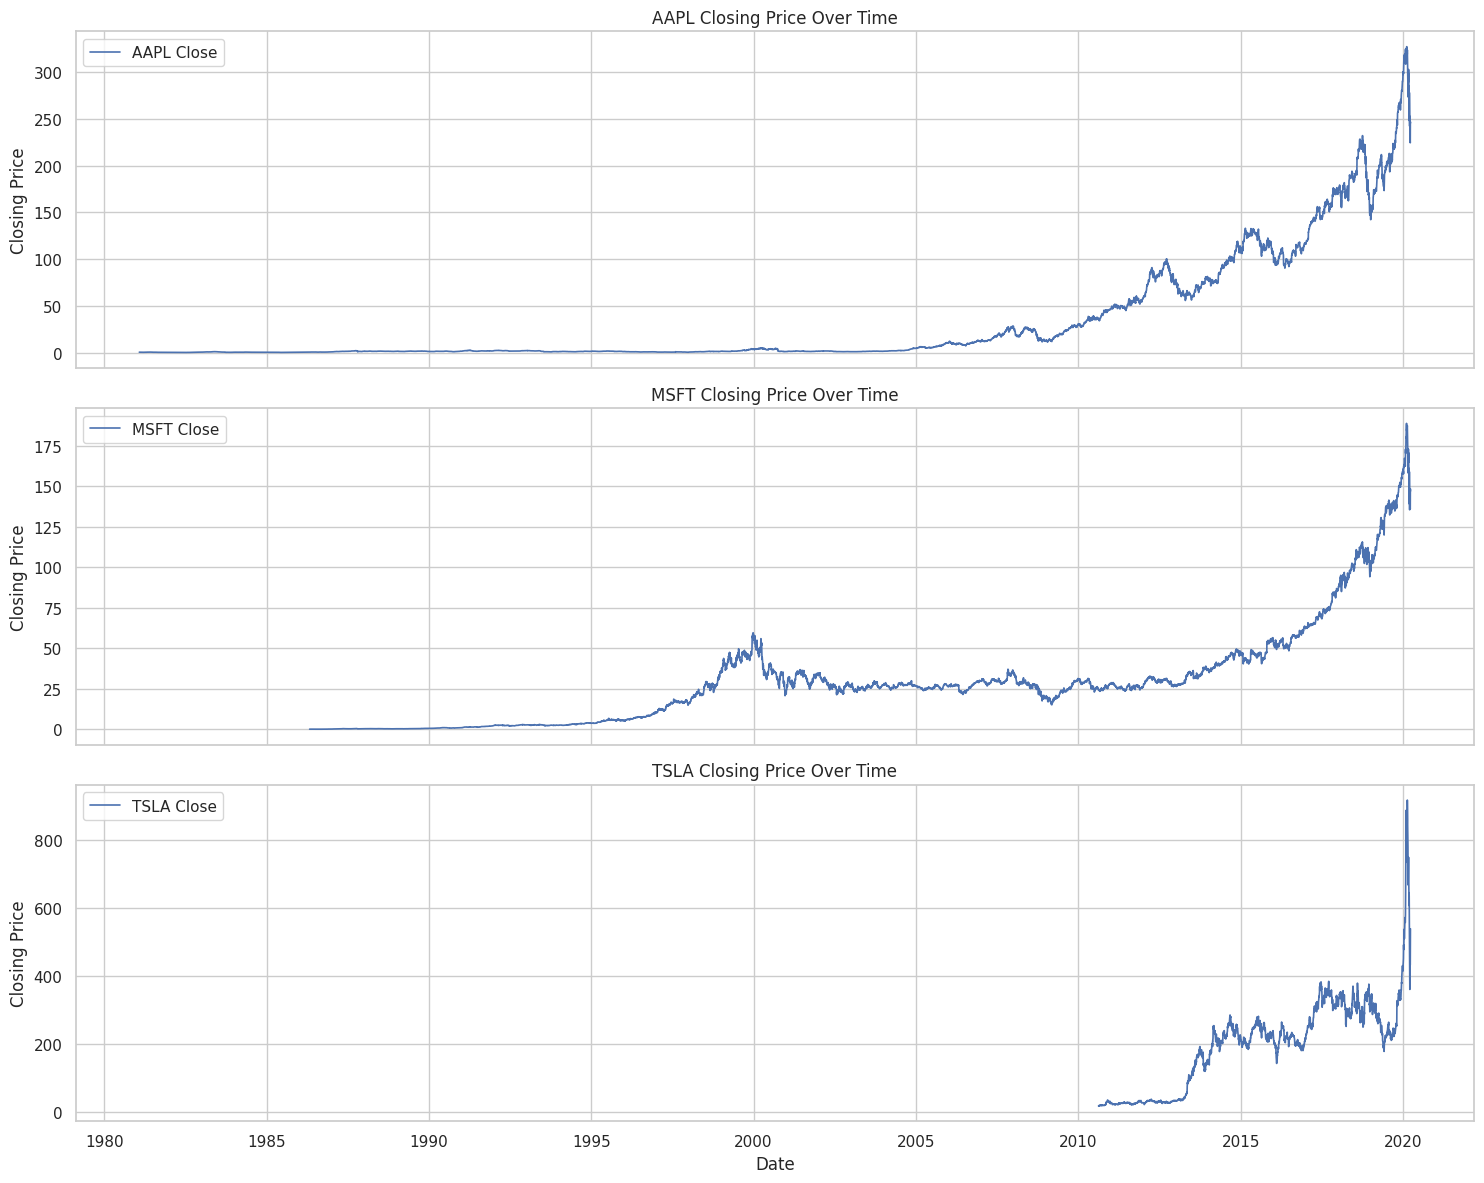

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

for ax, ticker in zip(axes, TICKERS):
    ticker_df = stock_data[
        stock_data["Symbol"] == ticker]

    ax.plot(ticker_df["Date"],
        ticker_df["Close"],
        label=f"{ticker} Close",
        linewidth=1.2)

    ax.set_title(f"{ticker} Closing Price Over Time")
    ax.set_ylabel("Closing Price")
    ax.legend()

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

**Interpretation:** Examine the overall trend, abrupt price changes, and periods of high or low variability. These patterns provide context for the classification task but do not establish that the future direction can be predicted reliably.

**3.2. Compare moving averages**

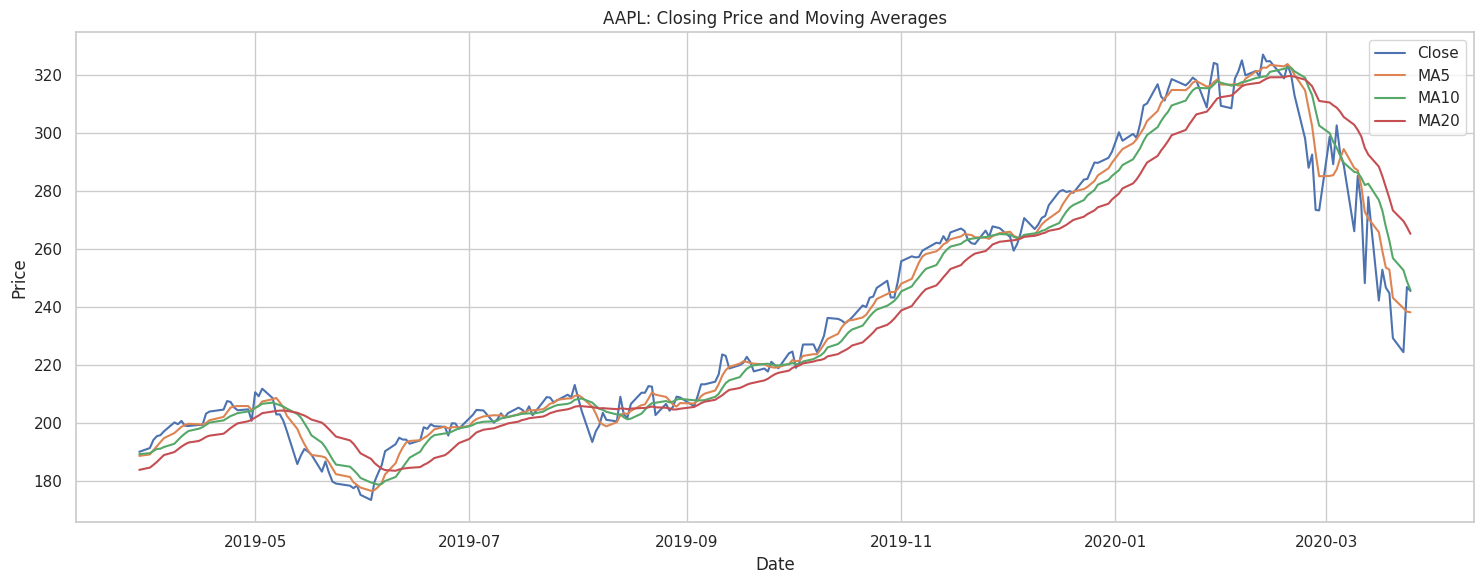

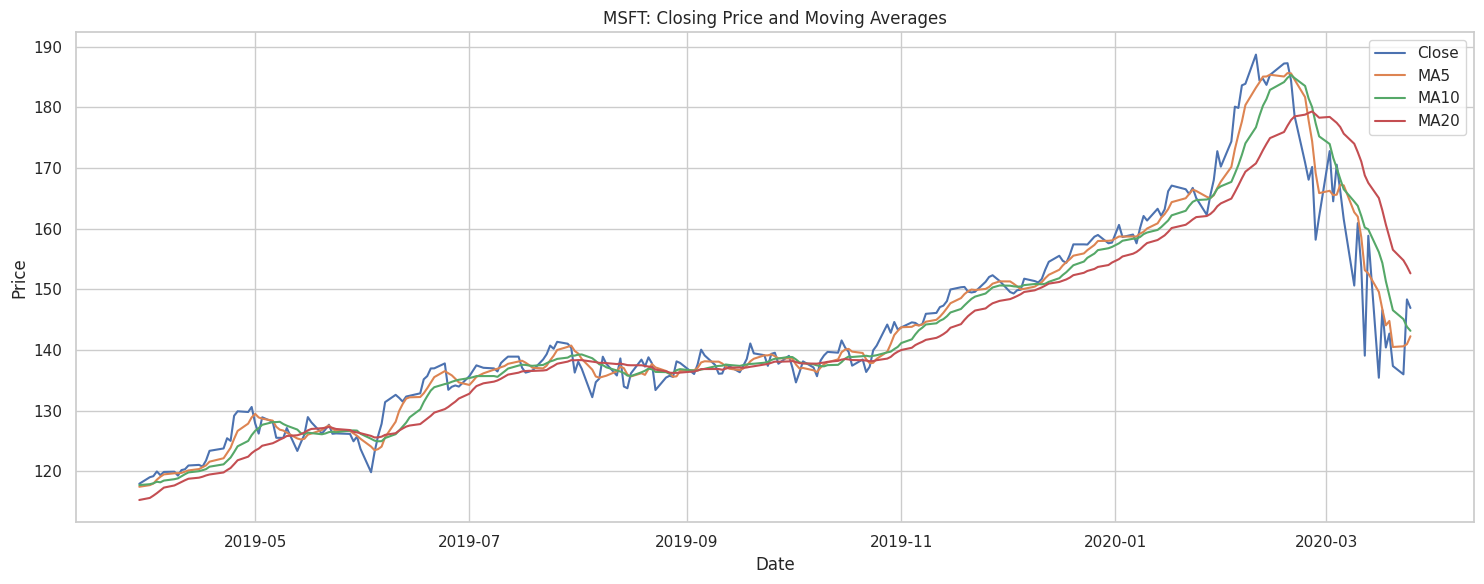

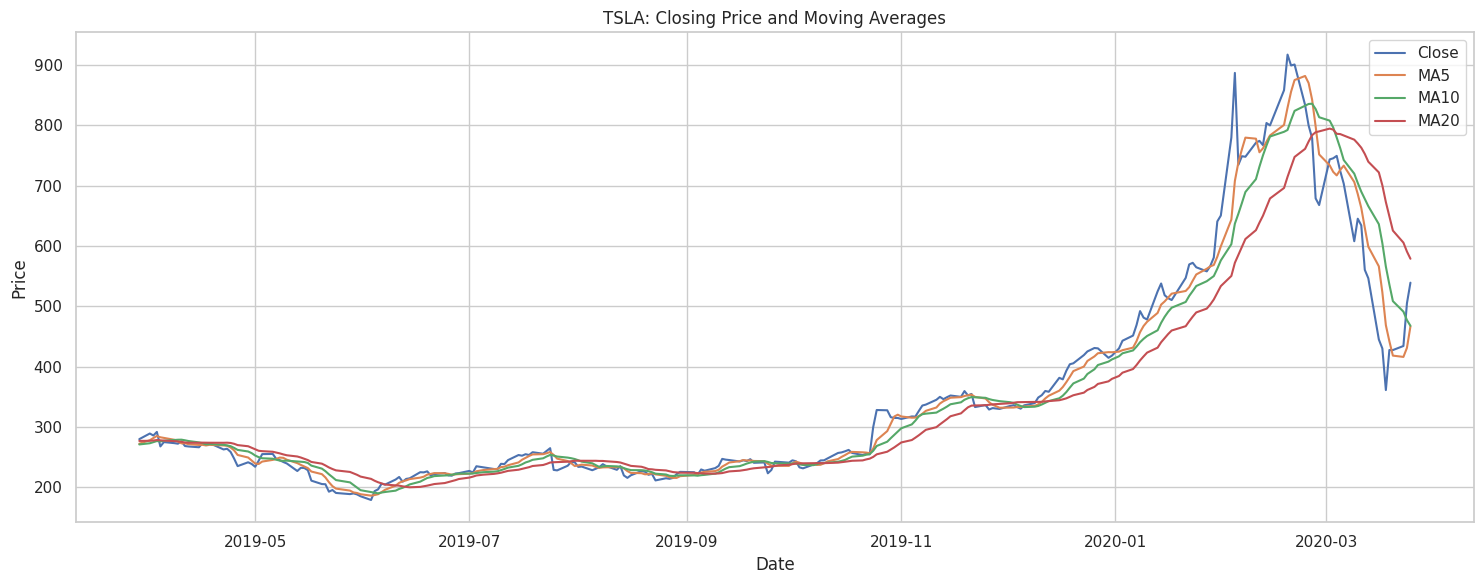

In [17]:
for ticker in TICKERS:
  plot_df = stock_data[stock_data["Symbol"] == ticker].tail(250)

  plt.figure(figsize=(15, 6))

  plt.plot(plot_df["Date"], plot_df["Close"],
          label="Close", linewidth=1.5)

  plt.plot(plot_df["Date"], plot_df["MA5"], label="MA5")
  plt.plot(plot_df["Date"], plot_df["MA10"], label="MA10")
  plt.plot(plot_df["Date"], plot_df["MA20"], label="MA20")

  plt.title(f"{ticker}: Closing Price and Moving Averages")
  plt.xlabel("Date")
  plt.ylabel("Price")
  plt.legend()
  plt.tight_layout()
  plt.show()

This visualization illustrates how moving averages smooth the price series at different time scales. A shorter moving average reacts more quickly to recent changes, while a longer one responds more gradually.

**3.3. Examine target distribution**

Before training, check whether the dataset contains similar numbers of positive and negative labels.

,No Increase (0),Increase (1)
Symbol,,
AAPL,4615,5256
MSFT,3899,4647
TSLA,1080,1339


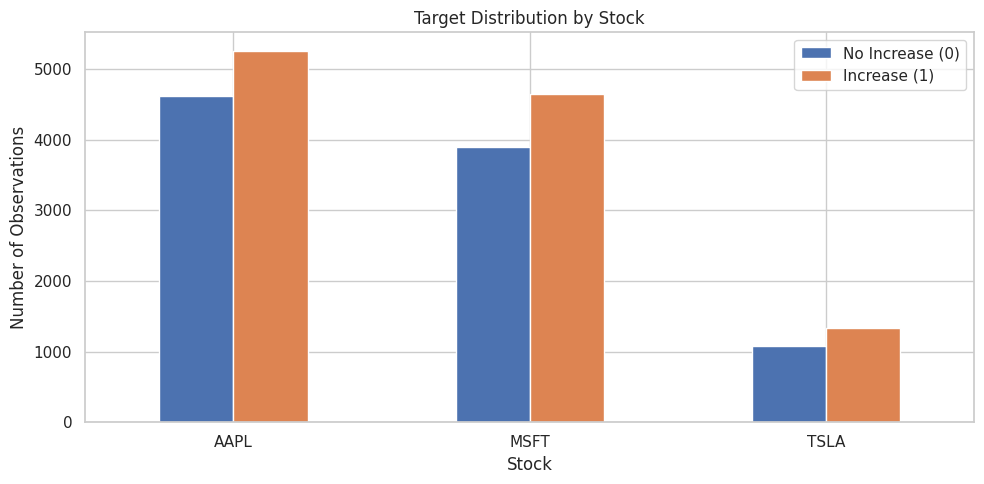

In [18]:
target_counts = (stock_data.groupby(["Symbol", "Target"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1], fill_value=0))

target_counts.columns = ["No Increase (0)", "Increase (1)"]
display(target_counts)

target_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Target Distribution by Stock")
plt.xlabel("Stock")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Calculate the class proportions for each stock:

In [19]:
class_distribution = (stock_data.groupby("Symbol")["Target"]
    .value_counts(normalize=True)
    .rename("Proportion")
    .reset_index())

display(class_distribution)

,Symbol,Target,Proportion
0,AAPL,1,0.532469
1,AAPL,0,0.467531
2,MSFT,1,0.543763
3,MSFT,0,0.456237
4,TSLA,1,0.553535
5,TSLA,0,0.446465


If the classes are imbalanced, accuracy alone may be misleading. Precision, recall, F1-score, and ROC-AUC will help us assess the models more comprehensively.

**3.4. Examine feature correlations**

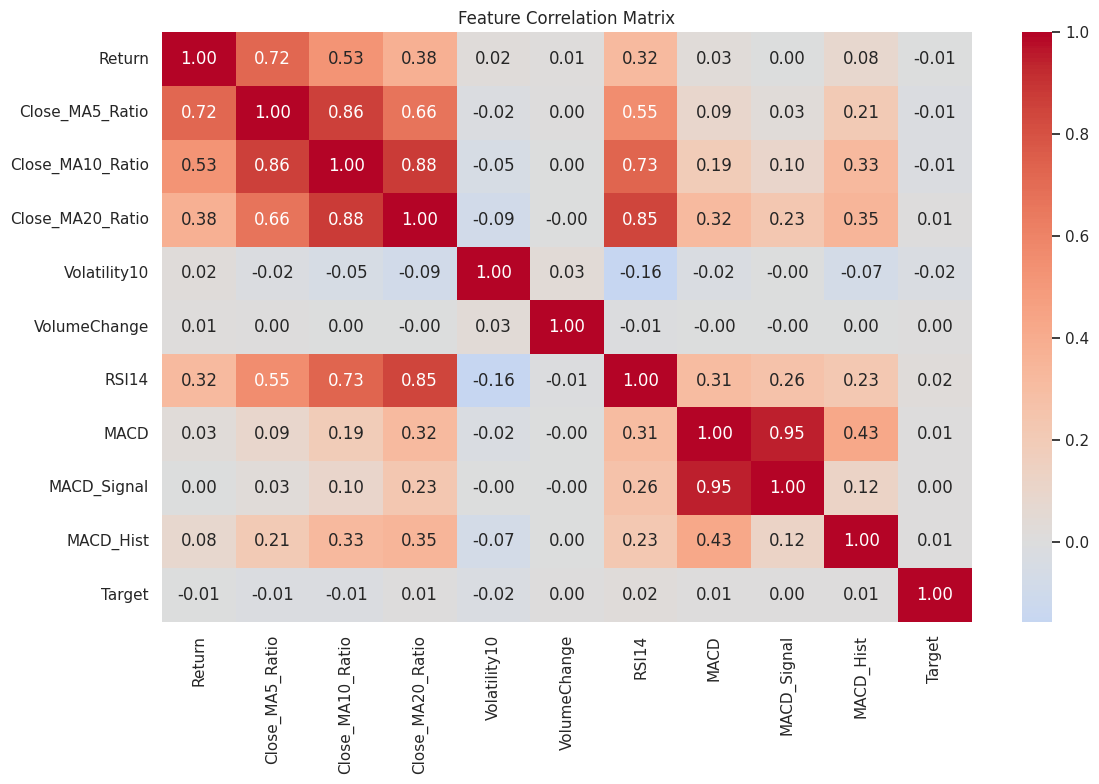

In [20]:
plt.figure(figsize=(12, 8))

sns.heatmap(stock_data[FEATURES + ["Target"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

Correlation can reveal relationships and redundancy between engineered features. However, correlation does not prove causation or establish predictive usefulness on unseen data.

### 4. Prepare data for machine learning

**4.1. Split the data chronologically**

For time-series classification, we must not randomly shuffle observations before splitting into training, validation, and test sets. Random splitting could allow observations from later dates to influence training while earlier dates appear in the test set.

For each stock, we will use:

```
- Training set: first 70% of observations.
- Validation set: next 15%.
- Test set: final 15%.
```

The validation set helps with model selection, while the test set is reserved for the final evaluation.

In [21]:
def chronological_split(df, train_ratio=0.70, val_ratio=0.15):
    df = df.sort_values("Date").reset_index(drop=True)

    n = len(df)
    train_end = int(n * train_ratio)
    val_end = int(n * (train_ratio + val_ratio))

    train = df.iloc[:train_end].copy()
    val = df.iloc[train_end:val_end].copy()
    test = df.iloc[val_end:].copy()

    return train, val, test


splits = {}

for ticker in TICKERS:
    ticker_df = stock_data[
        stock_data["Symbol"] == ticker]

    train_df, val_df, test_df = chronological_split(
        ticker_df,
        TRAIN_RATIO,
        VAL_RATIO)

    splits[ticker] = {"train": train_df,
        "val": val_df,
        "test": test_df}

    print(f"\n{ticker}")
    print("Train:", len(train_df),
        "| Validation:", len(val_df),
        "| Test:", len(test_df))

    print("Train dates:", train_df["Date"].min(),
        "to", train_df["Date"].max())

    print("Test dates:", test_df["Date"].min(),
        "to", test_df["Date"].max())


AAPL
Train: 6909 | Validation: 1481 | Test: 1481
Train dates: 1981-01-30 00:00:00 to 2008-06-18 00:00:00
Test dates: 2014-05-08 00:00:00 to 2020-03-25 00:00:00

MSFT
Train: 5982 | Validation: 1282 | Test: 1282
Train dates: 1986-04-30 00:00:00 to 2010-01-15 00:00:00
Test dates: 2015-02-23 00:00:00 to 2020-03-25 00:00:00

TSLA
Train: 1693 | Validation: 363 | Test: 363
Train dates: 2010-08-16 00:00:00 to 2017-05-05 00:00:00
Test dates: 2018-10-15 00:00:00 to 2020-03-25 00:00:00


Each stock is split independently to preserve its chronological order. The next step combines the stocks for a shared model while retaining the individual ticker identities for evaluation.

**4.2. Scale the numerical features**

Neural networks and Logistic Regression can benefit from standardized input features.

Standardization uses:

$$
z = \frac{x-\mu_{\text{train}}}{\sigma_{\text{train}}}
$$

The mean and standard deviation must be estimated from the training data only. Fitting a scaler on the entire dataset would leak information from the validation and test periods.

In [22]:
train_raw = pd.concat([splits[t]["train"] for t in TICKERS],
                      ignore_index=True).sort_values(["Symbol", "Date"])

val_raw = pd.concat([splits[t]["val"] for t in TICKERS],
                    ignore_index=True).sort_values(["Symbol", "Date"])

test_raw = pd.concat([splits[t]["test"] for t in TICKERS],
                     ignore_index=True).sort_values(["Symbol", "Date"])

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(train_raw[FEATURES])
X_val_scaled = scaler.transform(val_raw[FEATURES])
X_test_scaled = scaler.transform(test_raw[FEATURES])

y_train = train_raw["Target"].to_numpy()
y_val = val_raw["Target"].to_numpy()
y_test = test_raw["Target"].to_numpy()

print("Training features:", X_train_scaled.shape)
print("Validation features:", X_val_scaled.shape)
print("Test features:", X_test_scaled.shape)

Training features: (14584, 10)
Validation features: (3126, 10)
Test features: (3126, 10)


The scaler is shared across the three stocks, allowing the model to learn common patterns in standardized features. This is a modeling choice, not a guarantee that the stocks have identical behavior.

4.3. Create a chronological data structure for sliding windows
An LSTM expects a three-dimensional input:

$$
X \in \mathbb{R}^{N \times T \times F}
$$

where:
- \(N\) is the number of samples.
- \(T\) is the number of historical trading days.
- \(F\) is the number of features per day.
For example, a window of 20 days with 10 features has the shape (samples, 20, 10).

To build these windows correctly, we first create scaled feature arrays for each stock in chronological order. The scaler is still fitted only on training observations.

In [23]:
scaled_by_ticker = {}

for ticker in TICKERS:
    ticker_df = stock_data[stock_data["Symbol"]
                           == ticker].sort_values("Date").reset_index(drop=True)

    # Transform all observations using the training-fitted scaler
    X_all = scaler.transform(ticker_df[FEATURES])

    y_all = ticker_df["Target"].to_numpy()

    # Match rows to their chronological split
    train_dates = set(splits[ticker]["train"]["Date"])
    val_dates = set(splits[ticker]["val"]["Date"])
    test_dates = set(splits[ticker]["test"]["Date"])

    dates = ticker_df["Date"]

    train_idx = np.flatnonzero(dates.isin(train_dates))
    val_idx = np.flatnonzero(dates.isin(val_dates))
    test_idx = np.flatnonzero(dates.isin(test_dates))

    scaled_by_ticker[ticker] = {
        "X": X_all,
        "y": y_all,
        "df": ticker_df,
        "train_idx": train_idx,
        "val_idx": val_idx,
        "test_idx": test_idx
    }

This preparation also allows the first validation or test sample to use historical observations immediately preceding its prediction date. Those observations are legitimately available at prediction time.

**4.4. Generate sliding windows**

Each input window contains the features from the previous TIMESTEPS observations, including the current day \(t\), and its target is the label associated with day \(t\). Since that label compares Close(t+1) against Close(t), the prediction is for the next observed trading day.

In [24]:
def make_windows(X, y, target_indices, timesteps=20):
    X_windows = []
    y_windows = []
    valid_indices = []

    for idx in target_indices:
        start = idx - timesteps + 1

        if start < 0:
            continue

        X_windows.append(X[start:idx + 1])
        y_windows.append(y[idx])
        valid_indices.append(idx)

    return (np.asarray(X_windows, dtype=np.float32),
        np.asarray(y_windows, dtype=np.int32),
        np.asarray(valid_indices, dtype=int))

Create separate windows for training, validation, and testing.

In [25]:
lstm_data = {}

for ticker in TICKERS:
    data = scaled_by_ticker[ticker]

    X_all = data["X"]
    y_all = data["y"]

    X_tr, y_tr, idx_tr = make_windows(X_all, y_all,
                                      data["train_idx"], TIMESTEPS)

    X_va, y_va, idx_va = make_windows(X_all, y_all,
                                      data["val_idx"], TIMESTEPS)

    X_te, y_te, idx_te = make_windows(X_all, y_all,
                                      data["test_idx"], TIMESTEPS)

    lstm_data[ticker] = {
        "X_train": X_tr,
        "y_train": y_tr,
        "idx_train": idx_tr,
        "X_val": X_va,
        "y_val": y_va,
        "idx_val": idx_va,
        "X_test": X_te,
        "y_test": y_te,
        "idx_test": idx_te
    }

    print(f"\n{ticker}")
    print("X_train:", X_tr.shape)
    print("X_val:", X_va.shape)
    print("X_test:", X_te.shape)


AAPL
X_train: (6890, 20, 10)
X_val: (1481, 20, 10)
X_test: (1481, 20, 10)

MSFT
X_train: (5963, 20, 10)
X_val: (1282, 20, 10)
X_test: (1282, 20, 10)

TSLA
X_train: (1674, 20, 10)
X_val: (363, 20, 10)
X_test: (363, 20, 10)


The windows do not cross ticker boundaries because each ticker is processed separately. The target dates in each set remain within that set, while the historical context can extend into the preceding period.

### 5. Baseline model: Logistic Regression

Before using an LSTM, we establish a simpler baseline. Logistic Regression estimates the probability of the positive class using a linear combination of the input features.

$$
P(y=1 \mid X) =
\frac{1}{1+e^{-(w^\top X+b)}}
$$

For the baseline, each sample uses the engineered features from a single trading day rather than a sequence of days. This gives us a useful reference for evaluating whether the sequential model improves on a simpler classifier.

**5.1. Train Logistic Regression**

In [26]:
baseline_model = LogisticRegression(max_iter=2000,
                                    class_weight="balanced",
                                    random_state=SEED)

baseline_model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)

The `class_weight="balanced"` option adjusts class weights based on their frequencies in the training set. This can be useful when the target classes are imbalanced.

**5.2. Generate predictions**

In [27]:
baseline_val_prob = baseline_model.predict_proba(X_val_scaled)[:, 1]
baseline_test_prob = baseline_model.predict_proba(X_test_scaled)[:, 1]

baseline_val_pred = (baseline_val_prob >= 0.5).astype(int)
baseline_test_pred = (baseline_test_prob >= 0.5).astype(int)

print("Baseline validation predictions:")
print(baseline_val_pred[:20])

print("\nBaseline test probabilities:")
print(np.round(baseline_test_prob[:10], 3))

Baseline validation predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1]

Baseline test probabilities:
[0.552 0.548 0.542 0.534 0.529 0.52  0.518 0.512 0.508 0.507]


A predicted probability above or equal to 0.5 is classified as an increase; otherwise, it is classified as no increase. This threshold can be changed using validation data, but it must not be tuned against the test labels.

### 6. Long Short-Term Memory (LSTM)

**6.1. What is an LSTM?**

Long Short-Term Memory is a type of recurrent neural network designed to learn relationships within sequential data. Unlike a standard feedforward classifier, an LSTM can process a sequence of historical feature vectors and maintain an internal state across the sequence.

In this project, the LSTM receives a sequence of 20 trading days and outputs one probability for the next-day increase class.

**6.2. Build the LSTM model**

The output layer contains one neuron with a sigmoid activation, producing a probability between 0 and 1. We use binary cross-entropy as the loss function because the target is binary.

The model has three principal components:

***
- **LSTM (64 units):** learns representations of the historical sequence.

- **Dense (32 units):** learns combinations of the sequential features.

- **Sigmoid output:** estimates the probability of the next-day increase.*
***

Dropout randomly disables a proportion of activations during training, helping reduce overfitting. Its presence does not guarantee that overfitting will be eliminated.

In [28]:
n_features = len(FEATURES)

lstm_model = Sequential([
    tf.keras.Input(shape=(TIMESTEPS, n_features)),
    LSTM(64, return_sequences=True),
    Dropout(0.50),
    LSTM(32, return_sequences=False),
    Dropout(0.50),
    Dense(32, activation="relu"),
    Dropout(0.50),
    Dense(1, activation="sigmoid")
])

lstm_model.compile(optimizer="adam", loss="binary_crossentropy",
                   metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 20, 64)         │        19,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,705 (127.75 KB)

 Trainable params: 32,705 (127.75 KB)

 Non-trainable params: 0 (0.00 B)

**6.3. Combine the LSTM training sequences**

The LSTM model will train on all three stocks. Each stock contributes its own chronological sequences, and no sequence contains observations from multiple tickers.

In [29]:
X_lstm_train = np.concatenate([lstm_data[t]["X_train"] for t in TICKERS])
y_lstm_train = np.concatenate([lstm_data[t]["y_train"] for t in TICKERS])

X_lstm_val = np.concatenate([lstm_data[t]["X_val"] for t in TICKERS])
y_lstm_val = np.concatenate([lstm_data[t]["y_val"] for t in TICKERS])

X_lstm_test = np.concatenate([lstm_data[t]["X_test"] for t in TICKERS])
y_lstm_test = np.concatenate([lstm_data[t]["y_test"] for t in TICKERS])

print("LSTM training:", X_lstm_train.shape)
print("LSTM validation:", X_lstm_val.shape)
print("LSTM test:", X_lstm_test.shape)

LSTM training: (14527, 20, 10)
LSTM validation: (3126, 20, 10)
LSTM test: (3126, 20, 10)


**6.4. Train the LSTM**

Early stopping monitors validation loss and restores the model weights from the best validation epoch. This helps limit unnecessary training when the model stops improving.

We use `shuffle=False` to preserve sample order during training. The sliding windows are already constructed chronologically, and keeping the order makes the experiment easier to interpret and reproduce.
6.5. Visualize training performance

To have finer control over our training process, we implemented a `CustomCallback` class with two primary features:

1. **Periodic Weight Checkpoints:** Saves the model weights to disk (e.g., `lstm_model_epoch_10.h5`) every 10 epochs. This ensures we have restore points in case of unexpected interruptions or for later analysis.
2. **Conditional Early Stopping:** Standard early stopping can sometimes halt training prematurely during noisy initial epochs. Our custom logic ensures that early stopping patience is **only** checked once the validation accuracy reaches at least **80%**. If accuracy is below this threshold, the patience counter (`wait`) is reset to 0. Once the model crosses the 80% mark, the patience starts tracking validation loss improvements to restore the best weights and prevent overfitting.

In [38]:
class CustomCallback(tf.keras.callbacks.Callback):
    def __init__(self, patience=7, save_freq=10):
        super(CustomCallback, self).__init__()
        self.patience = patience
        self.save_freq = save_freq
        self.best_val_loss = np.inf
        self.best_weights = None
        self.wait = 0

    def on_epoch_end(self, epoch, logs=None):
        current_epoch = epoch + 1
        val_acc = logs.get("val_accuracy", 0)
        val_loss = logs.get("val_loss", np.inf)

        # 1. Save model weights every 10 epochs
        if current_epoch % self.save_freq == 0:
            checkpoint_path = f"lstm_model_epoch_{current_epoch}.weights.h5"
            self.model.save_weights(checkpoint_path)
            print(f"\n[Callback] Model weights saved to {checkpoint_path} at epoch {current_epoch}.")

        # 2. Track early stopping criteria: only consider if validation accuracy is >= 80%
        if val_acc >= 0.80:
            if val_loss < self.best_val_loss:
                self.best_val_loss = val_loss
                self.best_weights = self.model.get_weights()
                self.wait = 0
            else:
                self.wait += 1
                if self.wait >= self.patience:
                    self.model.stop_training = True
                    print(f"\n[Callback] Training stopped early at epoch {current_epoch} because validation accuracy reached {val_acc*100:.2f}% (>= 80%) and validation loss did not improve for {self.patience} epochs.")
                    if self.best_weights is not None:
                        self.model.set_weights(self.best_weights)
        else:
            # If validation accuracy is below 80%, reset patience counter
            self.wait = 0

# Instantiate the custom callback
custom_callback = CustomCallback(patience=7, save_freq=10)

# Retrain the model using the custom callback
history = lstm_model.fit(X_lstm_train, y_lstm_train,
                         validation_data=(X_lstm_val, y_lstm_val),
                         epochs=EPOCHS, batch_size=BATCH_SIZE,
                         callbacks=[custom_callback],
                         shuffle=False, verbose=1)

Epoch 1/50
454/454 ━━━━━━━━━━━━━━━━━━━━ 19s 42ms/step - accuracy: 0.7002 - auc: 0.7850 - loss: 0.5457 - val_accuracy: 0.5179 - val_auc: 0.5217 - val_loss: 0.9276
Epoch 2/50
454/454 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.7091 - auc: 0.7973 - loss: 0.5327 - val_accuracy: 0.5221 - val_auc: 0.5188 - val_loss: 0.9666
Epoch 3/50
454/454 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.7085 - auc: 0.7981 - loss: 0.5301 - val_accuracy: 0.5365 - val_auc: 0.5311 - val_loss: 0.9062
Epoch 4/50
454/454 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.7148 - auc: 0.8038 - loss: 0.5249 - val_accuracy: 0.5282 - val_auc: 0.5158 - val_loss: 0.9293
Epoch 5/50
454/454 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.7235 - auc: 0.8142 - loss: 0.5139 - val_accuracy: 0.5272 - val_auc: 0.5133 - val_loss: 0.9641
Epoch 6/50
454/454 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.7266 - auc: 0.8187 - loss: 0.5087 - val_accuracy: 0.5240 - val_auc: 0.5242 - val_loss: 0.9409
Epoch 7/50
454/454 ━━━━━━━━━

**Troubleshooting & Optimization Note:**

If the model's accuracy is too low or not improving:
* **Model Persistence:** Since Keras models keep their weights in memory, running the training cell multiple times will continue training the existing weights rather than resetting them from scratch. If you want to start over, you will need to re-execute the model creation cell (`g0PV90dCn5mm`) to initialize a fresh set of weights.
* **Hyperparameter Tuning:** Consider adjusting the main training and structural settings defined in Section [Define project settings](#vBIatuKgUKMP):
  * **`TIMESTEPS`**: Try 10 or 30 days to see if a different sequential context length helps the LSTM capture better trends.
  * **`EPOCHS`**: Increase the number of epochs to allow for longer learning, or reduce it if the model begins to overfit.
  * **`BATCH_SIZE`**: Experiment with smaller (e.g., 16) or larger (e.g., 64) batch sizes to stabilize gradient updates.


**6.5. Visualize training performance**

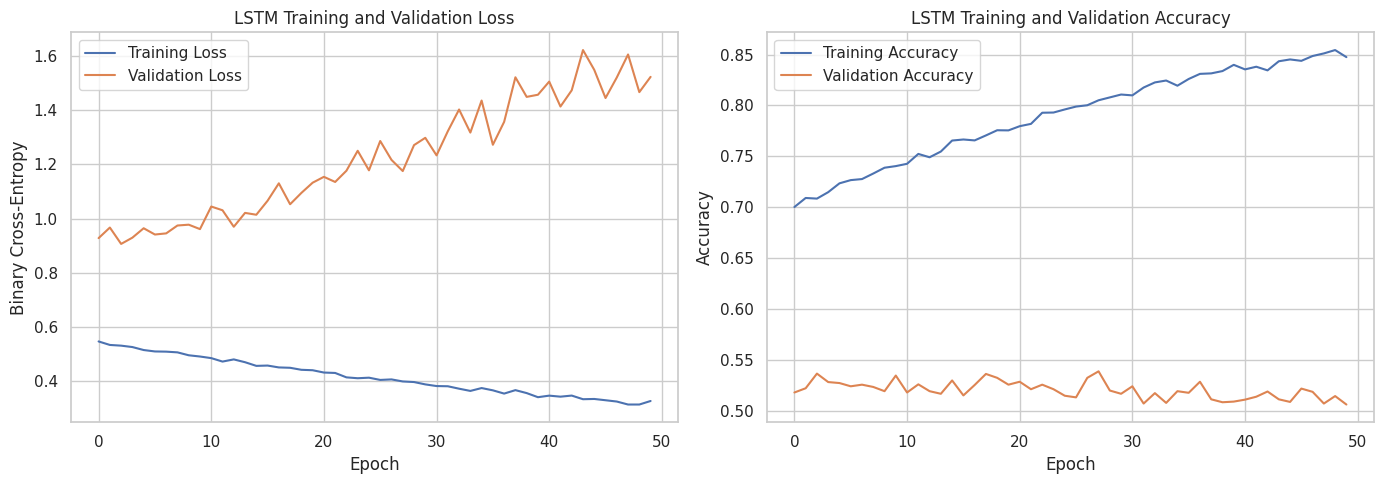

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["loss"],
             label="Training Loss")
axes[0].plot(history.history["val_loss"],
             label="Validation Loss")
axes[0].set_title("LSTM Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy")
axes[0].legend()

axes[1].plot(history.history["accuracy"],
             label="Training Accuracy")
axes[1].plot(history.history["val_accuracy"],
             label="Validation Accuracy")
axes[1].set_title("LSTM Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation:**

- If both training and validation loss decrease, the model is learning patterns that may generalize.

- If training loss continues to decrease while validation loss increases, the model may be overfitting.

- If both losses remain high, the model may be underfitting or the selected features may contain limited predictive information.

A lower training loss alone does not establish that the model is useful for predicting unseen market movements.

**6.6. Generate LSTM predictions**

In [40]:
lstm_test_prob = lstm_model.predict(X_lstm_test, verbose=0).ravel()
lstm_test_pred = (lstm_test_prob >= 0.5).astype(int)

print("Predicted probabilities:")
print(np.round(lstm_test_prob[:10], 3))

print("\nPredicted classes:")
print(lstm_test_pred[:10])

print("\nActual classes:")
print(y_lstm_test[:10])

Predicted probabilities:
[0.94  0.964 0.956 0.964 0.954 0.952 0.755 0.505 0.291 0.085]

Predicted classes:
[1 1 1 1 1 1 1 1 0 0]

Actual classes:
[1 1 1 1 1 1 1 1 1 1]


The predicted probabilities represent the model's estimated probability of a next-day increase. They should not be interpreted as guaranteed outcomes or necessarily well-calibrated real-world probabilities.

### 7. Model evaluation

We evaluate both models using the same core classification metrics.

| Metric           | What it measures                                                                     |
| ---------------- | ------------------------------------------------------------------------------------ |
| Accuracy         | Proportion of all predictions that are correct                                       |
| Precision        | Proportion of predicted increases that are actual increases                          |
| Recall           | Proportion of actual increases that are correctly identified                         |
| F1-score         | Harmonic mean of precision and recall                                                |
| Confusion matrix | Counts of correct and incorrect predictions for each class                           |
| ROC-AUC          | Ability to rank positive cases above negative cases across classification thresholds |

For this binary task, class 1 is the positive class.

**7.1. Define a reusable evaluation function**

In [41]:
def evaluate_classifier(y_true, y_pred, y_prob,
                        model_name="Model"):
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

    # ROC-AUC requires both classes to be present
    if len(np.unique(y_true)) == 2:
        results["ROC-AUC"] = roc_auc_score(y_true, y_prob)
    else:
        results["ROC-AUC"] = np.nan

    return results

**7.2. Evaluate Logistic Regression**

In [42]:
baseline_results = evaluate_classifier(y_test,
    baseline_test_pred,
    baseline_test_prob,
    model_name="Logistic Regression")

display(pd.DataFrame([baseline_results]))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.508317,0.588202,0.56564,0.576701,0.493899


**7.3. Evaluate LSTM**

In [46]:
lstm_results = evaluate_classifier(y_lstm_test,
    lstm_test_pred,
    lstm_test_prob,
    model_name="LSTM")

display(pd.DataFrame([lstm_results]))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,LSTM,0.496481,0.593771,0.473798,0.527043,0.494051


**Note:** The Logistic Regression and LSTM test sets are close in scope but may not contain exactly the same observations, because LSTM requires a complete historical window. For a strict head-to-head comparison, align the test dates before drawing conclusions.


**7.4. Confusion matrices**
The confusion matrix provides a more detailed view of the predictions.
- True negative (TN): correctly predicts no increase.
- False positive (FP): predicts an increase when the next close does not increase.
- False negative (FN): misses an actual increase.
- True positive (TP): correctly predicts an increase.

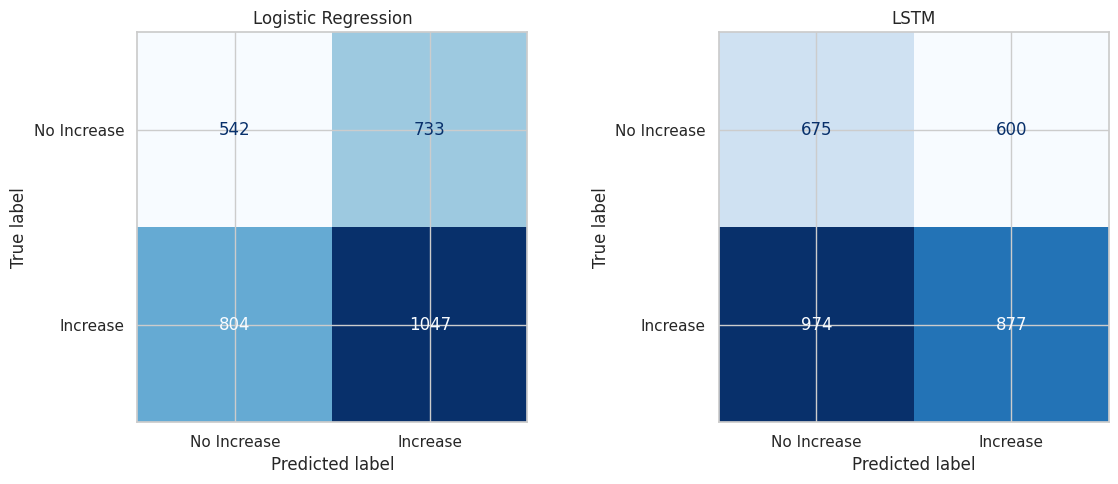

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, baseline_test_pred),
    display_labels=["No Increase", "Increase"]).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(
    confusion_matrix(y_lstm_test, lstm_test_pred),
    display_labels=["No Increase", "Increase"]).plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False)

axes[1].set_title("LSTM")

plt.tight_layout()
plt.show()

Compare the number of false positives and false negatives. In a real trading application, these errors may have different consequences, depending on the strategy and transaction costs.

**7.5. Classification reports**

In [47]:
print("Logistic Regression")
print(classification_report(
        y_test,
        baseline_test_pred,
        labels=[0, 1],
        target_names=["No Increase", "Increase"],
        zero_division=0))

print("LSTM")
print(classification_report(
        y_lstm_test,
        lstm_test_pred,
        labels=[0, 1],
        target_names=["No Increase", "Increase"],
        zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

 No Increase       0.40      0.43      0.41      1275
    Increase       0.59      0.57      0.58      1851

    accuracy                           0.51      3126
   macro avg       0.50      0.50      0.50      3126
weighted avg       0.51      0.51      0.51      3126

LSTM
              precision    recall  f1-score   support

 No Increase       0.41      0.53      0.46      1275
    Increase       0.59      0.47      0.53      1851

    accuracy                           0.50      3126
   macro avg       0.50      0.50      0.49      3126
weighted avg       0.52      0.50      0.50      3126



The classification report provides per-class precision, recall, and F1-score, alongside overall summaries. This is especially useful if one class appears more frequently than the other.

**7.6. ROC curves**

ROC curves illustrate the trade-off between the true-positive rate and false-positive rate at different probability thresholds.

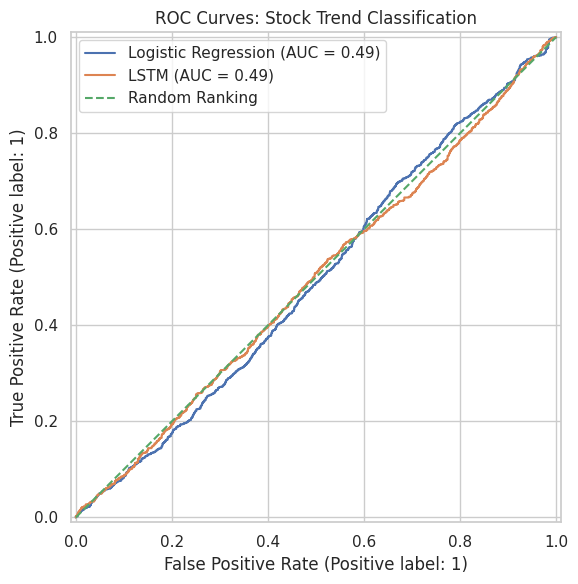

In [48]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(y_test,
    baseline_test_prob,
    name="Logistic Regression",
    ax=ax)

RocCurveDisplay.from_predictions(y_lstm_test,
    lstm_test_prob,
    name="LSTM",
    ax=ax)

ax.plot([0, 1], [0, 1],
    linestyle="--",
    label="Random Ranking")

ax.set_title("ROC Curves: Stock Trend Classification")
ax.legend()
plt.tight_layout()
plt.show()

An ROC-AUC of 0.5 indicates no better-than-random ranking in expectation, while a value closer to 1.0 indicates stronger separation between the two classes. It is still necessary to evaluate results across different periods before concluding that a model has stable predictive ability.

### 8. Compare the two models

**8.1. Create a comparison table**

In [49]:
comparison = pd.DataFrame([baseline_results,
    lstm_results]).set_index("Model")

display(comparison.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.5083,0.5882,0.5656,0.5767,0.4939
LSTM,0.4965,0.5938,0.4738,0.5270,0.4941


Visualize the main metrics:

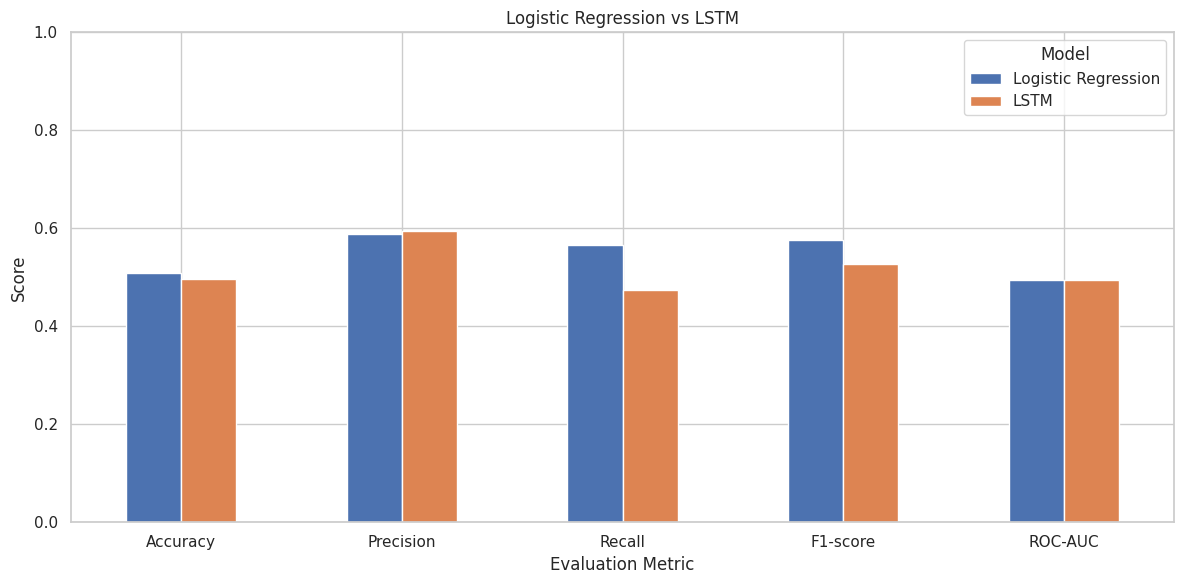

In [50]:
metrics_to_plot = ["Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"]

comparison[metrics_to_plot].T.plot(
    kind="bar",
    figsize=(12, 6))

plt.title("Logistic Regression vs LSTM")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

Use this table to compare the measured performance rather than assuming that LSTM will outperform Logistic Regression simply because it is a more complex model.

**8.2. Evaluate performance by stock**

A combined model score can conceal differences between Apple, Microsoft, and Tesla. The following cell evaluates each model on each ticker's own chronological test observations.

In [51]:
per_stock_results = []

for ticker in TICKERS:
    # Logistic Regression: use this ticker's test rows
    ticker_test = splits[ticker]["test"]

    X_ticker_test = scaler.transform(
        ticker_test[FEATURES])

    y_ticker_test = ticker_test["Target"].to_numpy()

    lr_prob = baseline_model.predict_proba(
        X_ticker_test)[:, 1]

    lr_pred = (lr_prob >= 0.5).astype(int)

    per_stock_results.append(evaluate_classifier(
            y_ticker_test,
            lr_pred,
            lr_prob,
            model_name=f"{ticker} - Logistic Regression"))

    # LSTM: use the same ticker's test windows
    data = lstm_data[ticker]

    y_ticker_lstm = data["y_test"]

    lstm_prob = lstm_model.predict(data["X_test"],
                                   verbose=0).ravel()

    lstm_pred = (lstm_prob >= 0.5).astype(int)

    per_stock_results.append(
        evaluate_classifier(
            y_ticker_lstm,
            lstm_pred,
            lstm_prob,
            model_name=f"{ticker} - LSTM"))

per_stock_comparison = pd.DataFrame(per_stock_results).set_index("Model")

display(per_stock_comparison.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
AAPL - Logistic Regression,0.5321,0.6129,0.5472,0.5782,0.5372
AAPL - LSTM,0.5098,0.5857,0.5588,0.5719,0.5108
MSFT - Logistic Regression,0.5008,0.5771,0.6237,0.5995,0.4545
MSFT - LSTM,0.4930,0.6166,0.4062,0.4898,0.4982
TSLA - Logistic Regression,0.4380,0.5314,0.4326,0.4769,0.4592
TSLA - LSTM,0.4545,0.5594,0.3721,0.4469,0.4403


This comparison reveals whether a model's results are reasonably consistent across the selected stocks or whether its performance varies substantially by company.

The Logistic Regression results use all eligible engineered-feature rows in each stock's test period, while the LSTM uses rows with sufficient preceding history. For the most rigorous comparison, match the exact test dates between the two models.

### Extra: Strategies to Improve LSTM Performance

Predicting daily stock market direction is notoriously difficult (often yielding around 50% to 54% accuracy due to market efficiency and high noise). If the model is hovering around 50% accuracy, here are the most effective ways to improve its predictive power:

#### 1. Feature Engineering & Selection
* **Add more expressive technical indicators:** Incorporate volatility bands (Bollinger Bands), Average True Range (ATR), Stochastic Oscillators, or momentum indicators.
* **Incorporate multi-asset dependencies:** Include market indices (S&P 500), volatility indexes (VIX), bond yields, or macroeconomic factors.
* **Use fundamental data or sentiment:** Merge news sentiment, Twitter sentiment analysis, or quarterly earnings metrics.

#### 2. Architecture & Regularization Adjustments
* **Go deeper or wider:** Try stacking two LSTM layers (e.g., first layer with `return_sequences=True`) or increase the units (e.g., 128 units).
* **Adjust Dropout rates:** Since overfitting is a major issue in financial series, try raising the dropout rate to `0.4` or `0.5`.
* **L1/L2 Weight Regularization:** Apply activity or kernel regularizers to prevent weights from blowing up.

#### 3. Labeling and Target Engineering
* **Change the prediction horizon:** Predicting next-day direction is highly noisy. Try predicting the trend over 5 trading days (`shift(-5)`) or 10 trading days.
* **Use a Triple Barrier Method:** Instead of simple binary price increases, define target labels based on whether the price hits an upper profit-take boundary, a lower stop-loss boundary, or flatlines before a time limit.

#### 4. Optimization Hyperparameters
* **Learning Rate Decay:** Use a learning rate scheduler to reduce the learning rate dynamically as validation loss plateaus.
* **Optimizer:** Try alternative optimizers like `RMSprop` or custom learning rates with `Adam(learning_rate=0.0001)`.
* **Tune Window Length (`TIMESTEPS`):** Try shrinking the window to 10 days (less noise) or expanding it to 45 days (longer-term trends).

### 9. Experiment: Compare different window lengths

The window length determines how much historical information the LSTM receives. We can compare 10, 20, and 30 trading days using the same chronological training and validation periods.

In [52]:
def build_lstm(timesteps, n_features):
    model = Sequential([
        tf.keras.Input(
            shape=(timesteps, n_features)),
        LSTM(64),
        Dropout(0.30),
        Dense(32, activation="relu"),
        Dropout(0.20),
        Dense(1, activation="sigmoid")])

    model.compile(optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"])

    return model

The following helper builds sequences from the already scaled ticker data. It reuses the existing training-fitted scaler and does not fit a new scaler on the test set.

In [54]:
window_results = []

for window in [10, 20, 30]:
    print(f"\n--- Training LSTM with lookback window of {window} days ---")
    X_tr_parts, y_tr_parts = [], []
    X_va_parts, y_va_parts = [], []
    X_te_parts, y_te_parts = [], []

    for ticker in TICKERS:
        data = scaled_by_ticker[ticker]

        X_tr, y_tr, _ = make_windows(
            data["X"], data["y"],
            data["train_idx"], window)

        X_va, y_va, _ = make_windows(
            data["X"], data["y"],
            data["val_idx"], window)

        X_te, y_te, _ = make_windows(
            data["X"], data["y"],
            data["test_idx"], window)

        X_tr_parts.append(X_tr)
        y_tr_parts.append(y_tr)

        X_va_parts.append(X_va)
        y_va_parts.append(y_va)

        X_te_parts.append(X_te)
        y_te_parts.append(y_te)

    X_tr = np.concatenate(X_tr_parts)
    y_tr = np.concatenate(y_tr_parts)

    X_va = np.concatenate(X_va_parts)
    y_va = np.concatenate(y_va_parts)

    X_te = np.concatenate(X_te_parts)
    y_te = np.concatenate(y_te_parts)

    model = build_lstm(window, len(FEATURES))

    callback = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True)

    model.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=20,
        batch_size=BATCH_SIZE,
        callbacks=[callback],
        shuffle=False,
        verbose=1)

    probabilities = model.predict(
        X_te, verbose=0).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    result = evaluate_classifier(
        y_te,
        predictions,
        probabilities,
        model_name=f"LSTM - {window} days")

    result["Window"] = window
    window_results.append(result)

window_comparison = pd.DataFrame(window_results)

display(window_comparison.set_index("Window").round(4))


--- Training LSTM with lookback window of 10 days ---
Epoch 1/20
455/455 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.5211 - loss: 0.6974 - val_accuracy: 0.5451 - val_loss: 0.6890
Epoch 2/20
455/455 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.5290 - loss: 0.6919 - val_accuracy: 0.5457 - val_loss: 0.6898
Epoch 3/20
455/455 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.5392 - loss: 0.6903 - val_accuracy: 0.5387 - val_loss: 0.6898
Epoch 4/20
455/455 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.5369 - loss: 0.6896 - val_accuracy: 0.5547 - val_loss: 0.6898
Epoch 5/20
455/455 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.5403 - loss: 0.6892 - val_accuracy: 0.5509 - val_loss: 0.6901
Epoch 6/20
455/455 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.5420 - loss: 0.6881 - val_accuracy: 0.5387 - val_loss: 0.6909

--- Training LSTM with lookback window of 20 days ---
Epoch 1/20
454/454 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.5205 - loss: 0.6965 - val_accuracy: 0.5470 - val_loss

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
Window,,,,,,
10,LSTM - 10 days,0.5940,0.5979,0.9600,0.7369,0.4994
20,LSTM - 20 days,0.5867,0.5991,0.9130,0.7235,0.5131
30,LSTM - 30 days,0.5899,0.6000,0.9222,0.7270,0.5116


This experiment can help determine whether a shorter or longer lookback window is more useful for this dataset. Since each experiment uses the same held-out test period, use validation performance to select the window length, then reserve the test results for final reporting. If the test results are repeatedly used to choose settings, they become part of the model-selection process.

## 10. Conclusion and further improvements

### 10.1. Project summary

This project develops a binary stock-market trend classification system using historical data for AAPL, MSFT, and TSLA.

The project includes:

- Data acquisition and cleaning using Pandas.
- Target construction from the next trading day's closing price.
- Feature engineering using returns, moving averages, rolling volatility, volume changes, RSI, and MACD.
- Exploratory analysis of price trends, class distributions, and feature correlations.
- Chronological training, validation, and test splitting.
- Feature scaling fitted exclusively on training observations.
- Sliding-window sequence generation for LSTM.
- A Logistic Regression baseline and an LSTM classifier.
- Evaluation using Accuracy, Precision, Recall, F1-score, confusion matrices, and ROC-AUC.
- Model comparison overall and by ticker.

### 10.2. Limitations

1\. Stock movements are difficult to predict. Historical prices and technical indicators alone may not contain sufficient information to predict future market direction reliably.

2\. Class labels simplify market behavior. A very small increase and a large increase are both labeled `1`. Likewise, a small decrease and a substantial decline are both labeled `0`.

3\. Transaction costs are not included. High classification accuracy does not necessarily imply a profitable trading strategy. Trading fees, slippage, taxes, and the timing of trades must be considered.

4\. Historical performance may not generalize. Market behavior changes over time. A model that performs well during one period may fail in another.

5\. The three stocks do not represent the entire market. Results from AAPL, MSFT, and TSLA should not automatically be generalized to other stocks or asset classes.

6\. The experiment has modeling limitations. A shared model may learn patterns that differ between companies. Feature selection, hyperparameter tuning, and class imbalance can also influence performance.

### 10.3. Further improvements

| Improvement                          | Purpose                                                                                   |
| ------------------------------------ | ----------------------------------------------------------------------------------------- |
| Compare 10-, 20-, and 30-day windows | Test different historical contexts                                                        |
| Add GRU                              | Compare a simpler recurrent architecture with LSTM                                        |
| Tune hyperparameters                 | Investigate units, dropout, learning rate, and batch size                                 |
| Add market indices                   | Incorporate broader market movements, ensuring their data is available at prediction time |
| Use walk-forward validation          | Evaluate model stability across multiple chronological periods                            |
| Calibrate probabilities              | Check whether predicted probabilities correspond to observed frequencies                  |
| Backtest a trading strategy          | Evaluate returns after transaction costs and risk constraints                             |
| Compare with simple baselines        | Include majority-class prediction and previous-direction prediction                       |

### 10.4. Final discussion questions

1. Does LSTM outperform Logistic Regression on the same test dates?
2. Does performance differ between Apple, Microsoft, and Tesla?
3. Is accuracy sufficient when the target classes are imbalanced?
4. How does the lookback window affect the model's performance?
5. Does a higher ROC-AUC correspond to a better F1-score at the 0.5 threshold?
6. What additional data or validation methods could improve confidence in the results?
7. Why is a model with strong classification metrics not necessarily a profitable trading system?

The main outcome of this project is not to prove that stock movements can be predicted with certainty. It is to demonstrate a complete, reproducible time-series classification experiment and critically evaluate what its results actually establish.